# Problem 14: Student Performance Prediction using an Artificial Neural Network
**Course:** Bio Inspired Computing  |  **Assigned algorithm:** Artificial Neural Network (ANN)

**Task:** Train an ANN to predict student performance categories (*At-Risk / Average / High*) from sample academic and attendance data.

### Bio-inspiration
An ANN is modelled on the brain: each artificial **neuron** sums weighted inputs (like dendrites collecting signals), applies a non-linear **activation** (like a neuron firing past a threshold), and passes the result on through **synapse-like weights** that are strengthened or weakened by learning (Hebbian-style adaptation, here done with back-propagation).

### Notebook roadmap (maps to the evaluation rubric)
| Step | Section | Rubric item |
|---|---|---|
| 1 | Problem formulation & representation | Problem-solving approach |
| 2 | Dataset creation (or load your own CSV) | Problem-solving approach |
| 3 | Exploratory data analysis (EDA) | Correctness & interpretability |
| 4 | Pre-processing | Problem-solving approach |
| 5 | ANN built **from scratch in NumPy** (forward pass, back-propagation, Adam) + gradient check | Concept application |
| 6 | Training & learning curves | Correctness & execution |
| 7 | Evaluation: confusion matrix, ROC, per-class metrics | Correctness & execution |
| 8 | Interpretation: permutation feature importance, PCA view | Meaningful output |
| 9 | **Original contribution:** Genetic Algorithm (another bio-inspired method) to evolve the ANN hyper-parameters, compared against random search | Implementation & originality |
| 10 | Baseline comparison + robustness over seeds | Meaningful output |
| 11 | Predict for a new student, conclusion | Meaningful output |

## Step 0 - Setup

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import time, copy, warnings
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             roc_curve, auc, f1_score)
from sklearn.preprocessing import label_binarize
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
CLASS_NAMES = ["At-Risk", "Average", "High"]
PALETTE = {"At-Risk": "#d62728", "Average": "#ff9f1c", "High": "#2a9d8f"}
print("Setup complete.")

Setup complete.


## Step 1 - Problem formulation & representation
* **Input vector (6 features):** `attendance_pct`, `study_hours_week`, `prev_cgpa`, `midterm_score`, `assignment_score`, `quiz_score`
* **Output:** one of 3 classes - **0 = At-Risk, 1 = Average, 2 = High** (multi-class classification)
* **Objective function:** minimise **categorical cross-entropy** + L2 weight penalty
* **Constraints / strategy:** stratified train/validation/test split (70/15/15), standardised inputs, early stopping on validation loss (prevents over-fitting), softmax output so predictions are class probabilities.

## Step 2 - Dataset
No real student data was supplied, so we generate a **realistic synthetic dataset** (1500 students). A hidden "ability" variable drives all scores, and a **non-linear attendance penalty** is added (students below ~65% attendance are hit disproportionately). That non-linearity is exactly where a neural network beats a purely linear model.

> **Using your own data?** Set `USE_OWN_CSV = True`, upload a CSV with the same six feature columns plus a `performance` column, and re-run.

In [2]:
USE_OWN_CSV = False          # <-- set True and upload a file to use real data
CSV_PATH = "students.csv"

FEATURES = ["attendance_pct", "study_hours_week", "prev_cgpa",
            "midterm_score", "assignment_score", "quiz_score"]

def generate_student_data(n=1500, seed=SEED):
    rng = np.random.default_rng(seed)
    ability = rng.normal(0, 1, n)                                   # hidden latent ability
    attendance = np.clip(76 + 8*ability + rng.normal(0, 10, n), 35, 100)
    study      = np.clip(10 + 2.5*ability + rng.normal(0, 3.5, n), 0, 30)
    prev_cgpa  = np.clip(7.0 + 0.9*ability + rng.normal(0, 0.8, n), 3, 10)
    midterm    = np.clip(62 + 12*ability + rng.normal(0, 9, n), 0, 100)
    assignment = np.clip(70 + 9*ability + rng.normal(0, 8, n), 0, 100)
    quiz       = np.clip(60 + 11*ability + rng.normal(0, 10, n), 0, 100)
    df = pd.DataFrame(dict(attendance_pct=attendance, study_hours_week=study, prev_cgpa=prev_cgpa,
                           midterm_score=midterm, assignment_score=assignment, quiz_score=quiz))
    z = (df - df.mean()) / df.std()
    score = (0.30*z.midterm_score + 0.20*z.assignment_score + 0.15*z.quiz_score +
             0.20*z.attendance_pct + 0.10*z.study_hours_week + 0.25*z.prev_cgpa)
    score -= 0.9*np.maximum(0, (65 - df.attendance_pct)/10)         # non-linear attendance penalty
    score += rng.normal(0, 0.35, n)                                  # real-world noise
    q1, q2 = np.quantile(score, [0.25, 0.75])
    df["performance"] = np.where(score < q1, 0, np.where(score < q2, 1, 2))
    return df.round(2)

if USE_OWN_CSV:
    df = pd.read_csv(CSV_PATH)
else:
    df = generate_student_data()
    df.to_csv("students.csv", index=False)
print("Shape:", df.shape)
df.head(8)

Shape: (1500, 7)


,attendance_pct,study_hours_week,prev_cgpa,midterm_score,assignment_score,quiz_score,performance
0,72.77,15.13,6.08,67.68,80.23,64.38,1
1,61.43,9.81,6.93,49.04,43.26,37.38,0
2,95.26,18.76,6.63,78.78,72.32,69.26,1
3,86.83,6.93,8.48,78.75,78.03,58.89,2
4,58.27,4.19,4.68,11.72,54.28,50.41,0
5,70.57,5.13,7.11,51.28,52.47,72.95,1
6,55.95,3.41,7.71,54.50,56.45,66.25,0
7,73.04,12.92,5.91,45.41,60.75,50.17,1


## Step 3 - Exploratory data analysis

0 missing values


,count,mean,std,min,25%,50%,75%,max
attendance_pct,1500.0,75.38,12.55,35.00,66.71,75.09,84.23,100.00
study_hours_week,1500.0,9.97,4.20,0.00,7.13,9.85,12.64,24.19
prev_cgpa,1500.0,6.99,1.23,3.40,6.09,7.02,7.91,10.00
midterm_score,1500.0,61.76,15.15,11.72,51.23,61.69,72.45,100.00
assignment_score,1500.0,69.71,11.93,35.42,61.34,70.00,77.75,100.00
quiz_score,1500.0,59.35,15.07,14.42,49.43,59.34,69.65,100.00
performance,1500.0,1.00,0.71,0.00,0.75,1.00,1.25,2.00


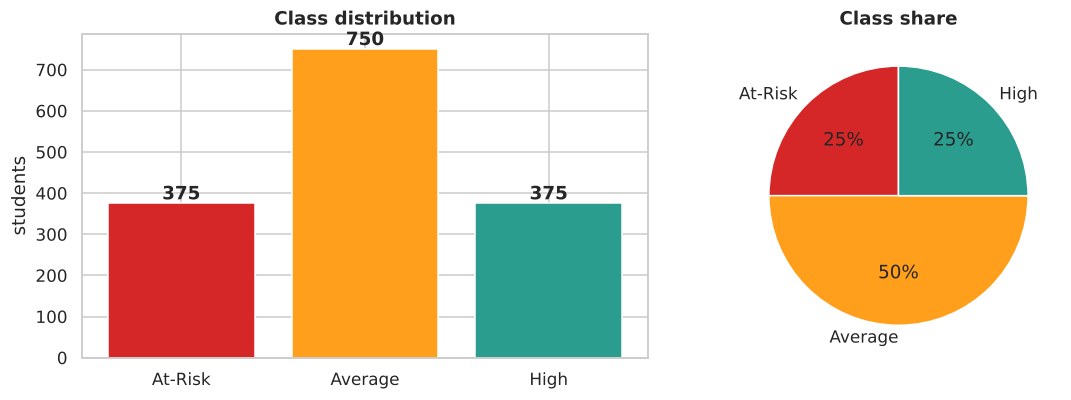

In [3]:
print(df.isna().sum().sum(), "missing values")
display(df.describe().T.round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
counts = df["performance"].map(dict(enumerate(CLASS_NAMES))).value_counts().reindex(CLASS_NAMES)
ax[0].bar(counts.index, counts.values, color=[PALETTE[c] for c in counts.index])
for i, v in enumerate(counts.values): ax[0].text(i, v+10, str(v), ha="center", fontweight="bold")
ax[0].set_title("Class distribution"); ax[0].set_ylabel("students")
ax[1].pie(counts.values, labels=counts.index, autopct="%1.0f%%", colors=[PALETTE[c] for c in counts.index], startangle=90)
ax[1].set_title("Class share")
plt.tight_layout(); plt.show()

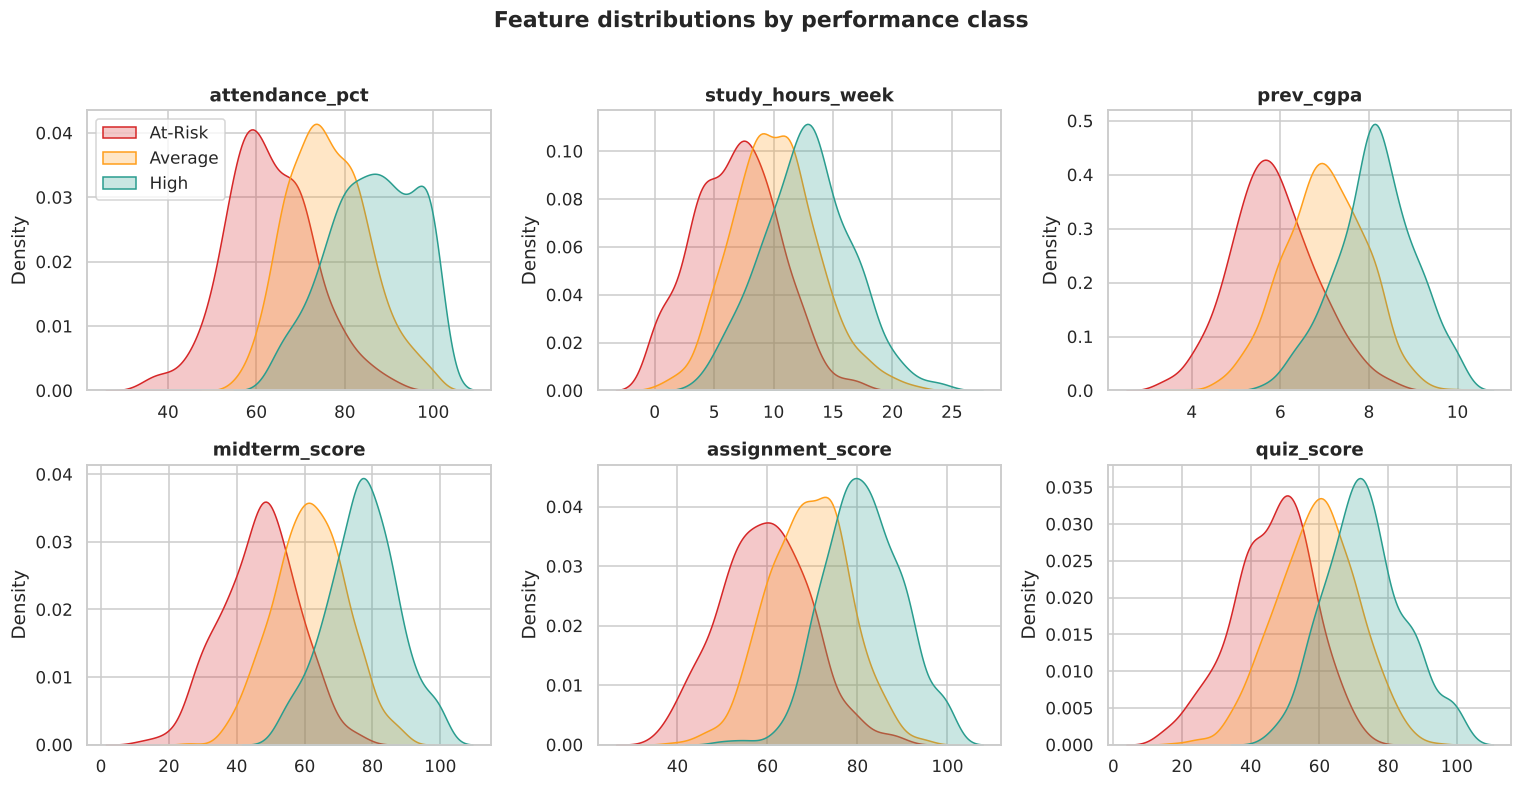

In [4]:
# Feature distributions split by class
lab = df["performance"].map(dict(enumerate(CLASS_NAMES)))
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, f in zip(axes.ravel(), FEATURES):
    for c in CLASS_NAMES:
        sns.kdeplot(df.loc[lab == c, f], ax=ax, label=c, color=PALETTE[c], fill=True, alpha=0.25)
    ax.set_title(f); ax.set_xlabel("")
axes[0, 0].legend()
plt.suptitle("Feature distributions by performance class", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

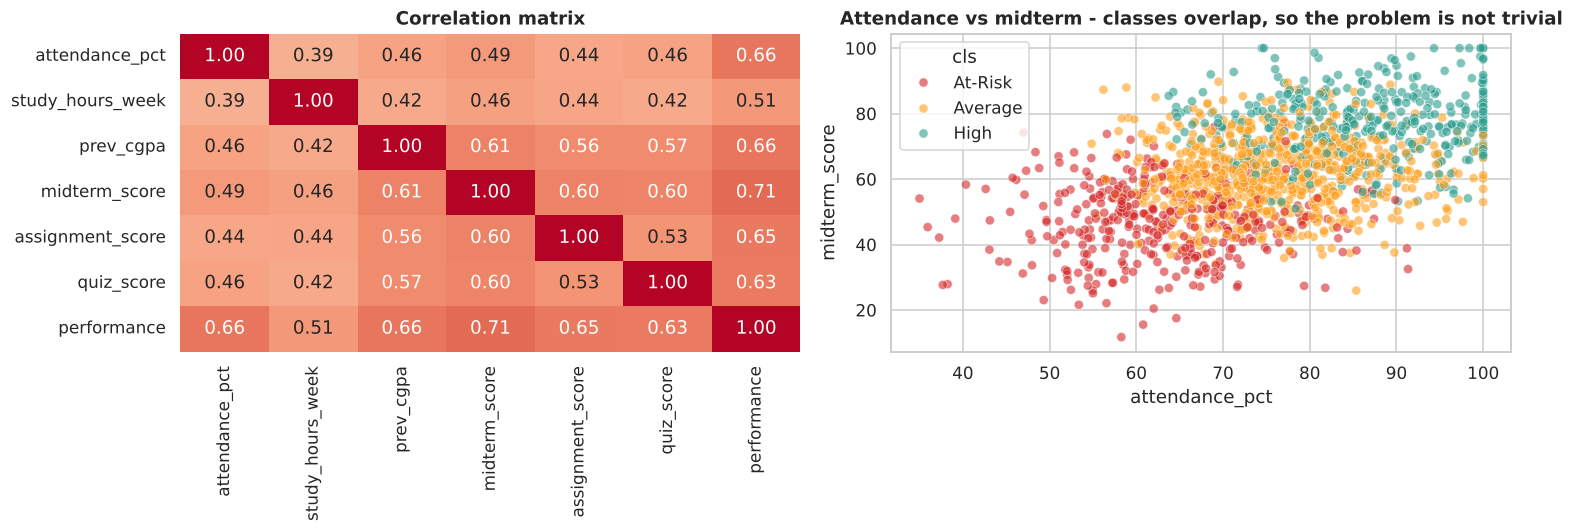

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(df[FEATURES + ["performance"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[0], cbar=False)
ax[0].set_title("Correlation matrix")
sns.scatterplot(data=df.assign(cls=lab), x="attendance_pct", y="midterm_score", hue="cls",
                palette=PALETTE, alpha=0.6, ax=ax[1], hue_order=CLASS_NAMES)
ax[1].set_title("Attendance vs midterm - classes overlap, so the problem is not trivial")
plt.tight_layout(); plt.show()

## Step 4 - Pre-processing
Stratified 70 / 15 / 15 split. The scaler is **fitted on the training set only** (no data leakage), then applied to validation and test. Labels are one-hot encoded for the softmax / cross-entropy loss.

In [6]:
X = df[FEATURES].values.astype(float)
y = df["performance"].values.astype(int)

X_tmp, X_te, y_tmp, y_te = train_test_split(X, y, test_size=0.15, stratify=y, random_state=SEED)
X_tr, X_va, y_tr, y_va = train_test_split(X_tmp, y_tmp, test_size=0.15/0.85, stratify=y_tmp, random_state=SEED)

scaler = StandardScaler().fit(X_tr)
X_tr_s, X_va_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_va), scaler.transform(X_te)

N_FEATURES, N_CLASSES = X.shape[1], 3
def one_hot(y): return np.eye(N_CLASSES)[y]
Y_tr, Y_va, Y_te = one_hot(y_tr), one_hot(y_va), one_hot(y_te)
print(f"train={len(y_tr)}  val={len(y_va)}  test={len(y_te)}")

train=1049  val=226  test=225


## Step 5 - The ANN, implemented from scratch (NumPy)
**Architecture:** Input (6) -> Dense + **ReLU** -> ... -> Dense + **Softmax** (3)

* **Forward pass:** `a(l) = ReLU(a(l-1) W(l) + b(l))`, final layer uses softmax
* **Loss:** cross-entropy + `(lambda/2) * sum(W^2)`
* **Back-propagation:** output error `dZ = (P - Y)/m`, propagated backwards through the weights with the ReLU derivative
* **Optimiser:** Adam (adaptive moment estimation), mini-batches
* **Initialisation:** He initialisation (suited to ReLU)
* **Early stopping:** restore the weights with the best validation loss

In [7]:
class ANN:
    """Fully-connected feed-forward neural network (ReLU hidden layers, softmax output)."""
    def __init__(self, layers, lr=0.01, l2=1e-4, seed=0):
        self.layers, self.lr, self.l2 = list(layers), lr, l2
        rng = np.random.default_rng(seed)
        self.W = [rng.normal(0, np.sqrt(2.0/layers[i]), (layers[i], layers[i+1])) for i in range(len(layers)-1)]
        self.b = [np.zeros((1, layers[i+1])) for i in range(len(layers)-1)]
        self.mW = [np.zeros_like(w) for w in self.W]; self.vW = [np.zeros_like(w) for w in self.W]
        self.mb = [np.zeros_like(b) for b in self.b]; self.vb = [np.zeros_like(b) for b in self.b]
        self.t = 0
        self.rng = rng

    @property
    def n_params(self): return sum(w.size + b.size for w, b in zip(self.W, self.b))

    @staticmethod
    def softmax(z):
        z = z - z.max(axis=1, keepdims=True)
        e = np.exp(z); return e / e.sum(axis=1, keepdims=True)

    def forward(self, X, keep=False):
        A, Z, a = [X], [], X
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            z = a @ W + b
            a = self.softmax(z) if i == len(self.W)-1 else np.maximum(0, z)
            Z.append(z); A.append(a)
        return (A, Z) if keep else a

    def loss(self, P, Y):
        ce = -np.mean(np.sum(Y * np.log(P + 1e-12), axis=1))
        return ce + 0.5 * self.l2 * sum((W**2).sum() for W in self.W)

    def backward(self, A, Z, Y):
        m, L = Y.shape[0], len(self.W)
        gW, gb = [None]*L, [None]*L
        dz = (A[-1] - Y) / m
        for i in reversed(range(L)):
            gW[i] = A[i].T @ dz + self.l2 * self.W[i]
            gb[i] = dz.sum(axis=0, keepdims=True)
            if i > 0:
                dz = (dz @ self.W[i].T) * (Z[i-1] > 0)
        return gW, gb

    def _adam(self, gW, gb, b1=0.9, b2=0.999, eps=1e-8):
        self.t += 1
        for i in range(len(self.W)):
            for p, g, m, v in ((self.W, gW, self.mW, self.vW), (self.b, gb, self.mb, self.vb)):
                m[i] = b1*m[i] + (1-b1)*g[i]
                v[i] = b2*v[i] + (1-b2)*g[i]**2
                p[i] -= self.lr * (m[i]/(1-b1**self.t)) / (np.sqrt(v[i]/(1-b2**self.t)) + eps)

    def predict_proba(self, X): return self.forward(X)
    def predict(self, X): return self.forward(X).argmax(axis=1)

    def fit(self, X, Y, Xv, Yv, epochs=200, batch_size=64, patience=25, verbose=False):
        hist = dict(train_loss=[], val_loss=[], train_acc=[], val_acc=[])
        best, best_w, wait = np.inf, None, 0
        n = X.shape[0]
        for ep in range(epochs):
            idx = self.rng.permutation(n)
            for s in range(0, n, batch_size):
                bi = idx[s:s+batch_size]
                A, Z = self.forward(X[bi], keep=True)
                gW, gb = self.backward(A, Z, Y[bi])
                self._adam(gW, gb)
            Pt, Pv = self.forward(X), self.forward(Xv)
            hist["train_loss"].append(self.loss(Pt, Y)); hist["val_loss"].append(self.loss(Pv, Yv))
            hist["train_acc"].append((Pt.argmax(1) == Y.argmax(1)).mean())
            hist["val_acc"].append((Pv.argmax(1) == Yv.argmax(1)).mean())
            if hist["val_loss"][-1] < best - 1e-5:
                best, wait = hist["val_loss"][-1], 0
                best_w = (copy.deepcopy(self.W), copy.deepcopy(self.b))
            else:
                wait += 1
                if wait >= patience: break
            if verbose and (ep % 20 == 0):
                print(f"epoch {ep:3d}  loss {hist['train_loss'][-1]:.4f}  val_acc {hist['val_acc'][-1]:.3f}")
        if best_w: self.W, self.b = best_w
        hist["best_epoch"] = int(np.argmin(hist["val_loss"]))
        return hist
print("ANN class defined.")

ANN class defined.


### Correctness check: numerical gradient check
We compare our analytic back-propagation gradients with finite-difference gradients on a tiny network. A relative error around 1e-7 or below confirms back-propagation is implemented correctly.

In [8]:
def gradient_check(seed=1):
    rng = np.random.default_rng(seed)
    Xg, Yg = rng.normal(size=(12, 6)), one_hot(rng.integers(0, 3, 12))
    net = ANN([6, 5, 4, 3], l2=1e-3, seed=seed)
    A, Z = net.forward(Xg, keep=True); gW, _ = net.backward(A, Z, Yg)
    worst, eps = 0.0, 1e-5
    for li in range(len(net.W)):
        for _ in range(8):
            i, j = rng.integers(net.W[li].shape[0]), rng.integers(net.W[li].shape[1])
            old = net.W[li][i, j]
            net.W[li][i, j] = old + eps; lp = net.loss(net.forward(Xg), Yg)
            net.W[li][i, j] = old - eps; lm = net.loss(net.forward(Xg), Yg)
            net.W[li][i, j] = old
            num = (lp - lm) / (2*eps); ana = gW[li][i, j]
            worst = max(worst, abs(num-ana) / max(1e-8, abs(num)+abs(ana)))
    return worst
err = gradient_check()
print(f"Max relative gradient error: {err:.2e}  ->", "PASS" if err < 1e-5 else "CHECK")

Max relative gradient error: 7.14e-08  -> PASS


### Network architecture diagram

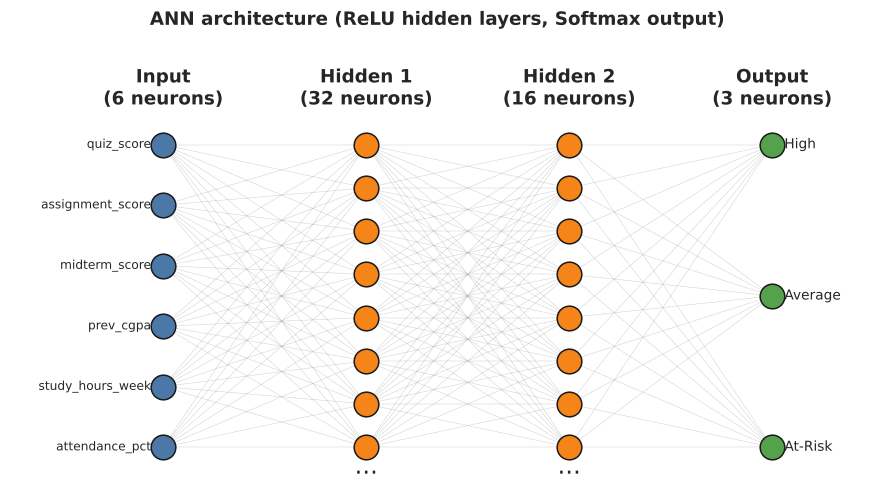

In [9]:
def draw_network(layers, names_in=FEATURES, names_out=CLASS_NAMES, cap=8):
    fig, ax = plt.subplots(figsize=(10, 5)); ax.axis("off")
    xs = np.linspace(0, 1, len(layers)); pos = []
    for li, n in enumerate(layers):
        shown = min(n, cap)
        ys = np.linspace(0.1, 0.9, shown) if shown > 1 else [0.5]
        pos.append([(xs[li], y) for y in ys])
    for a, b in zip(pos[:-1], pos[1:]):
        for (x1, y1) in a:
            for (x2, y2) in b: ax.plot([x1, x2], [y1, y2], color="#999", lw=0.3, alpha=0.5)
    cols = ["#4c78a8"] + ["#f58518"]*(len(layers)-2) + ["#54a24b"]
    for li, p in enumerate(pos):
        ax.scatter(*zip(*p), s=260, color=cols[li], zorder=3, edgecolor="k")
        label = "Input" if li == 0 else ("Output" if li == len(layers)-1 else f"Hidden {li}")
        ax.text(xs[li], 0.99, f"{label}\n({layers[li]} neurons)", ha="center", va="bottom", fontweight="bold")
        if layers[li] > cap: ax.text(xs[li], 0.03, "...", ha="center", fontsize=16)
    for (x, y), nme in zip(pos[0], names_in): ax.text(x-0.02, y, nme, ha="right", va="center", fontsize=8)
    for (x, y), nme in zip(pos[-1], names_out): ax.text(x+0.02, y, nme, ha="left", va="center", fontsize=9)
    ax.set_xlim(-0.25, 1.15); ax.set_ylim(0, 1.12)
    ax.set_title("ANN architecture (ReLU hidden layers, Softmax output)", pad=24)
    plt.show()
draw_network([N_FEATURES, 32, 16, N_CLASSES])

## Step 6 - Training the ANN (baseline hyper-parameters)

epoch   0  loss 0.5243  val_acc 0.796
epoch  20  loss 0.3146  val_acc 0.841

Trained in 0.1s | stopped at epoch 39 | best epoch 8 | params 803


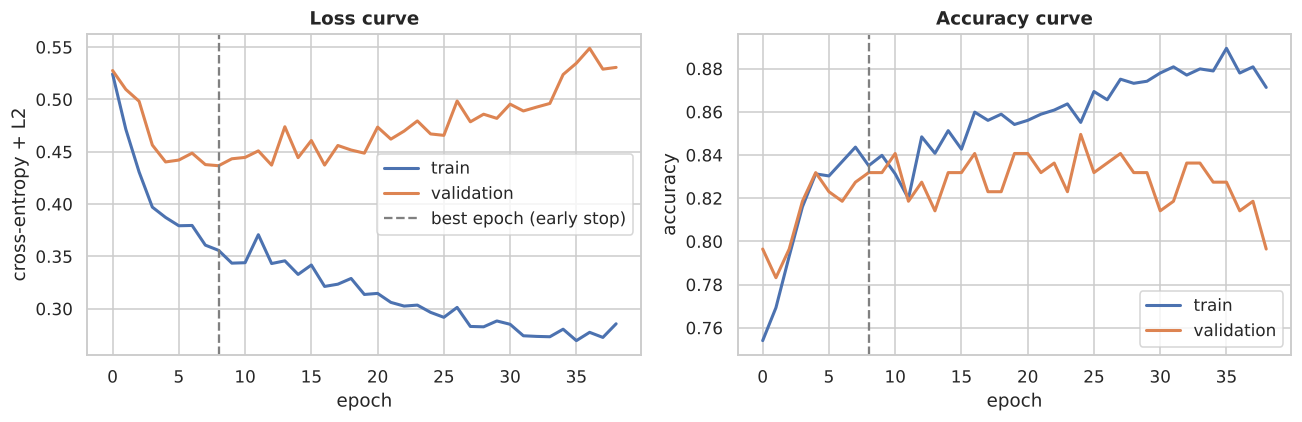

In [10]:
base_net = ANN([N_FEATURES, 32, 16, N_CLASSES], lr=0.01, l2=1e-4, seed=SEED)
t0 = time.time()
hist = base_net.fit(X_tr_s, Y_tr, X_va_s, Y_va, epochs=300, batch_size=64, patience=30, verbose=True)
print(f"\nTrained in {time.time()-t0:.1f}s | stopped at epoch {len(hist['val_loss'])} | best epoch {hist['best_epoch']} | params {base_net.n_params}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist["train_loss"], label="train", lw=2); ax[0].plot(hist["val_loss"], label="validation", lw=2)
ax[0].axvline(hist["best_epoch"], ls="--", c="gray", label="best epoch (early stop)")
ax[0].set_title("Loss curve"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("cross-entropy + L2"); ax[0].legend()
ax[1].plot(hist["train_acc"], label="train", lw=2); ax[1].plot(hist["val_acc"], label="validation", lw=2)
ax[1].axvline(hist["best_epoch"], ls="--", c="gray")
ax[1].set_title("Accuracy curve"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

## Step 7 - Evaluation on the unseen test set

Baseline ANN (test): accuracy = 0.8178 | macro-F1 = 0.8148

              precision    recall  f1-score   support

     At-Risk      0.870     0.714     0.784        56
     Average      0.805     0.841     0.823       113
        High      0.803     0.875     0.838        56

    accuracy                          0.818       225
   macro avg      0.826     0.810     0.815       225
weighted avg      0.821     0.818     0.817       225



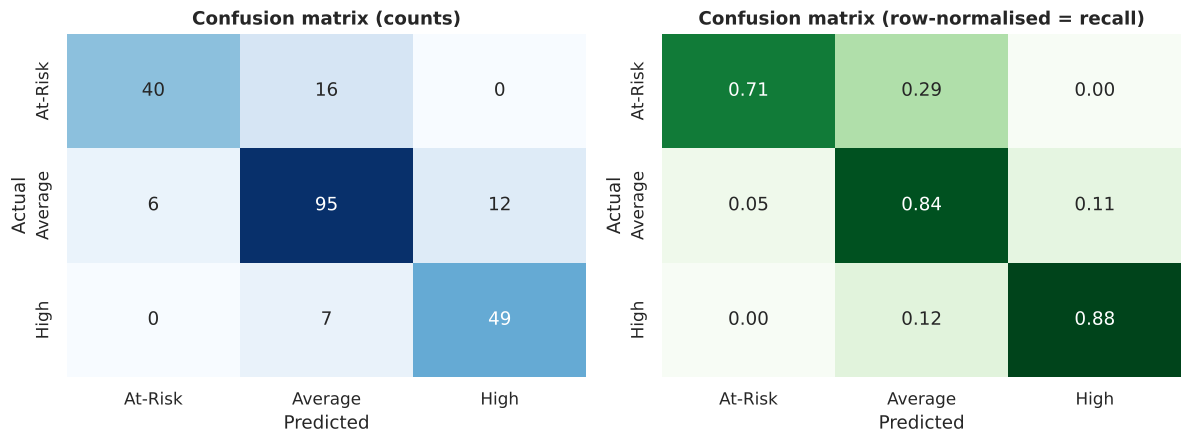

In [11]:
def evaluate(net, X, y, title="ANN"):
    P = net.predict_proba(X); pred = P.argmax(1)
    acc, f1 = accuracy_score(y, pred), f1_score(y, pred, average="macro")
    print(f"{title}: accuracy = {acc:.4f} | macro-F1 = {f1:.4f}\n")
    print(classification_report(y, pred, target_names=CLASS_NAMES, digits=3))
    return P, pred, acc, f1

P_te, pred_te, acc_te, f1_te = evaluate(base_net, X_te_s, y_te, "Baseline ANN (test)")

cm = confusion_matrix(y_te, pred_te)
cmn = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[0], cbar=False)
ax[0].set_title("Confusion matrix (counts)"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")
sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Greens", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[1], cbar=False)
ax[1].set_title("Confusion matrix (row-normalised = recall)"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Actual")
plt.tight_layout(); plt.show()

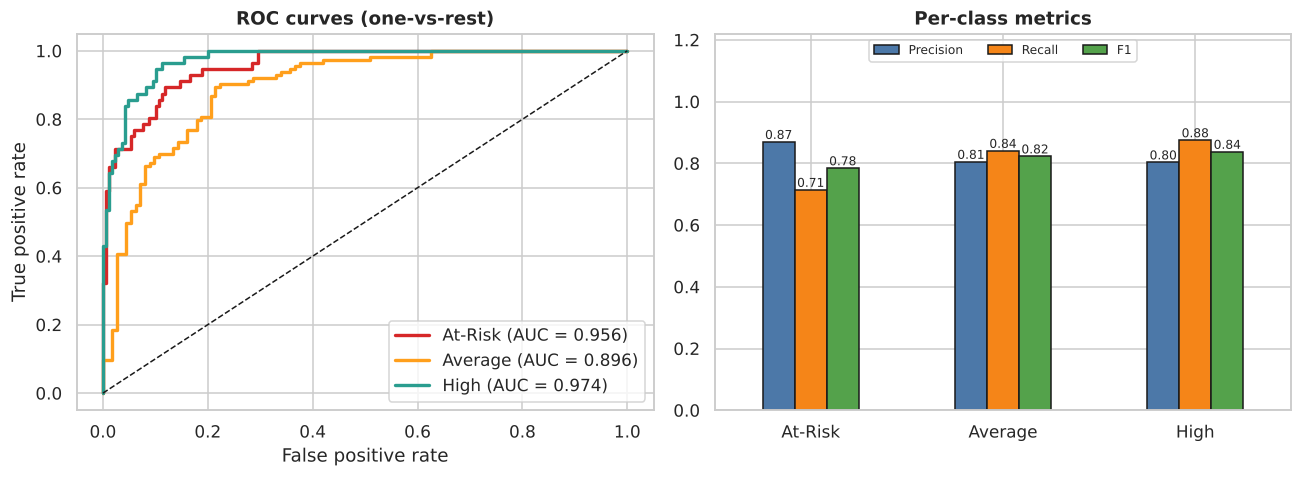

In [12]:
# One-vs-rest ROC curves + per-class precision / recall / F1
Yb = label_binarize(y_te, classes=[0, 1, 2])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for k, c in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(Yb[:, k], P_te[:, k])
    ax[0].plot(fpr, tpr, lw=2.2, color=PALETTE[c], label=f"{c} (AUC = {auc(fpr, tpr):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_title("ROC curves (one-vs-rest)")
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].legend(loc="lower right")

rep = classification_report(y_te, pred_te, target_names=CLASS_NAMES, output_dict=True)
metrics = pd.DataFrame({c: [rep[c]["precision"], rep[c]["recall"], rep[c]["f1-score"]] for c in CLASS_NAMES},
                       index=["Precision", "Recall", "F1"]).T
metrics.plot.bar(ax=ax[1], rot=0, color=["#4c78a8", "#f58518", "#54a24b"], edgecolor="k")
ax[1].set_ylim(0, 1.22); ax[1].legend(loc="upper center", ncol=3, fontsize=8); ax[1].set_title("Per-class metrics")
for cont in ax[1].containers: ax[1].bar_label(cont, fmt="%.2f", fontsize=8)
plt.tight_layout(); plt.show()

## Step 8 - Interpreting the network
**(a) Permutation feature importance** - shuffle one feature at a time on the test set; the larger the accuracy drop, the more the ANN relies on that feature.
**(b) PCA projection** - squash the 6-D space into 2-D to see where the ANN's mistakes sit (they should lie near the class borders).

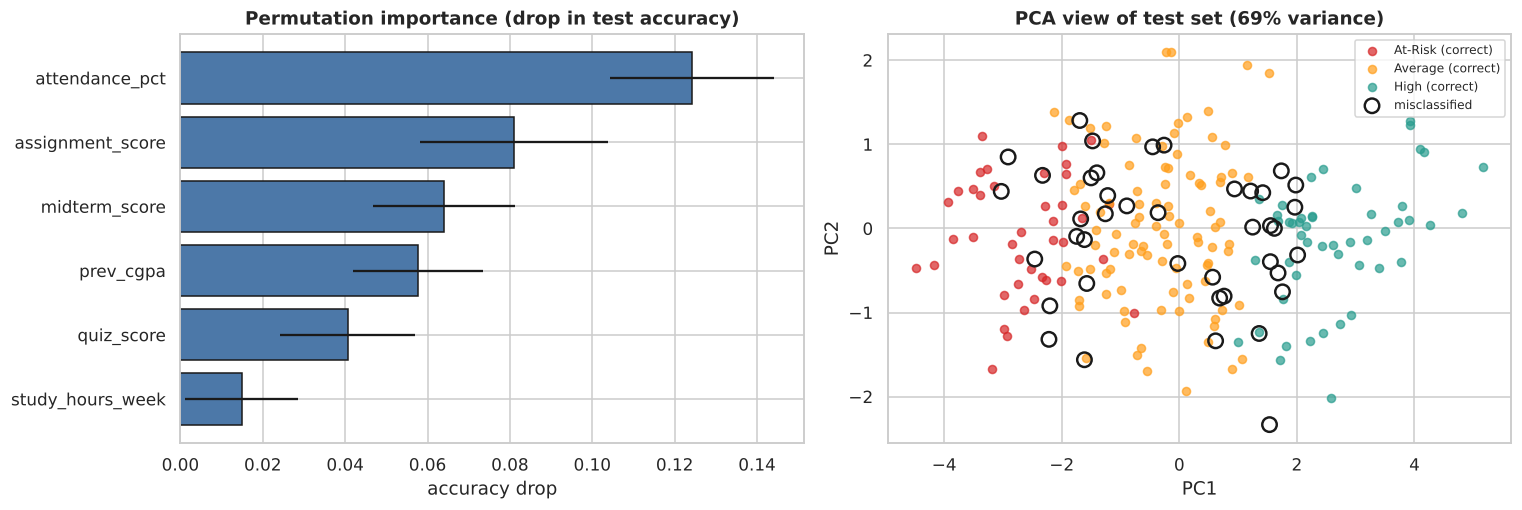

Most influential features: attendance_pct, assignment_score, midterm_score


In [13]:
def permutation_importance(net, X, y, repeats=20, seed=0):
    rng = np.random.default_rng(seed); base = accuracy_score(y, net.predict(X)); out = []
    for j in range(X.shape[1]):
        drops = []
        for _ in range(repeats):
            Xp = X.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
            drops.append(base - accuracy_score(y, net.predict(Xp)))
        out.append((np.mean(drops), np.std(drops)))
    return np.array(out)

imp = permutation_importance(base_net, X_te_s, y_te)
order = np.argsort(imp[:, 0])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].barh(np.array(FEATURES)[order], imp[order, 0], xerr=imp[order, 1], color="#4c78a8", edgecolor="k")
ax[0].set_title("Permutation importance (drop in test accuracy)"); ax[0].set_xlabel("accuracy drop")

pca = PCA(2).fit(X_tr_s); Z2 = pca.transform(X_te_s)
correct = pred_te == y_te
for k, c in enumerate(CLASS_NAMES):
    m = (y_te == k) & correct
    ax[1].scatter(Z2[m, 0], Z2[m, 1], s=28, color=PALETTE[c], alpha=0.7, label=f"{c} (correct)")
ax[1].scatter(Z2[~correct, 0], Z2[~correct, 1], s=90, facecolors="none", edgecolors="k", lw=1.6, label="misclassified")
ax[1].set_title(f"PCA view of test set ({pca.explained_variance_ratio_.sum()*100:.0f}% variance)")
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Most influential features:", ", ".join(np.array(FEATURES)[np.argsort(-imp[:, 0])][:3]))

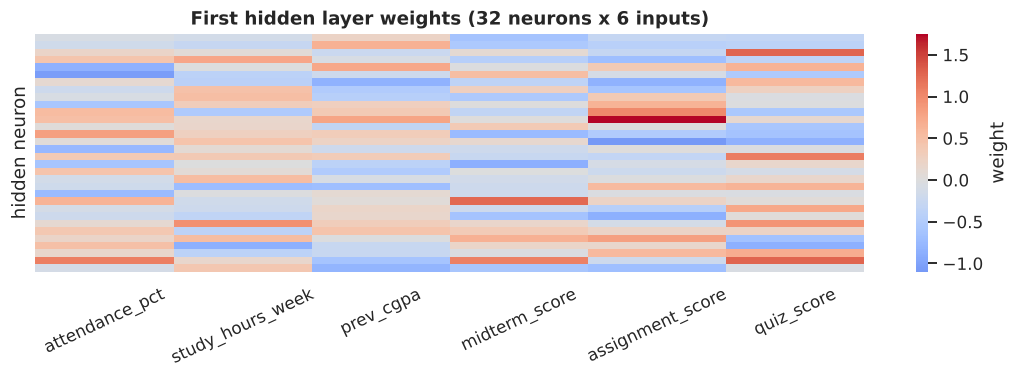

In [14]:
# Hidden-layer weight maps: what each first-layer neuron "listens to"
W1 = base_net.W[0]
plt.figure(figsize=(10, 3.6))
sns.heatmap(W1.T, cmap="coolwarm", center=0, xticklabels=FEATURES, yticklabels=False, cbar_kws={"label": "weight"})
plt.title(f"First hidden layer weights ({W1.shape[1]} neurons x {W1.shape[0]} inputs)")
plt.ylabel("hidden neuron"); plt.xticks(rotation=25); plt.tight_layout(); plt.show()

## Step 9 - Original contribution: a Genetic Algorithm to *evolve* the ANN
Choosing the number of neurons, learning rate and regularisation by hand is guesswork. Since the course is about **bio-inspired computing**, we use a second nature-inspired method - a **Genetic Algorithm (GA)** - to search for the best ANN design automatically. So the final system is a *neuro-evolution* pipeline: **evolution designs the brain, back-propagation trains it.**

| GA component | Choice |
|---|---|
| Chromosome | `[h1 (8-64 neurons), h2 (0-32 neurons, 0 = layer absent), learning rate (1e-3 to 5e-2, log-scale), L2 (1e-6 to 1e-2, log-scale)]` |
| Fitness | validation accuracy (small penalty on parameter count to prefer compact nets) |
| Selection | tournament (k = 3) |
| Crossover | uniform (each gene from either parent) |
| Mutation | Gaussian on neuron counts, log-Gaussian on rates, probability 0.25 per gene |
| Elitism | top 2 survive unchanged |

The GA only ever sees **training + validation data**; the test set stays untouched. We also run **random search with the same evaluation budget** to prove the evolutionary search adds value.

In [15]:
POP, GENS, ELITE, TOURN, P_MUT = 12, 10, 2, 3, 0.25
EPOCHS_GA = 80

def random_individual(rng):
    return dict(h1=int(rng.integers(8, 65)), h2=int(rng.integers(0, 33)),
                lr=float(10**rng.uniform(-3, np.log10(5e-2))), l2=float(10**rng.uniform(-6, -2)))

def build(ind, seed=0):
    layers = [N_FEATURES, ind["h1"]] + ([ind["h2"]] if ind["h2"] >= 4 else []) + [N_CLASSES]
    return ANN(layers, lr=ind["lr"], l2=ind["l2"], seed=seed)

_cache = {}
def fitness(ind):
    key = (ind["h1"], ind["h2"], round(ind["lr"], 6), round(ind["l2"], 8))
    if key not in _cache:
        net = build(ind, seed=SEED)
        h = net.fit(X_tr_s, Y_tr, X_va_s, Y_va, epochs=EPOCHS_GA, batch_size=64, patience=12)
        va = accuracy_score(y_va, net.predict(X_va_s))
        _cache[key] = va - 2e-6 * net.n_params
    return _cache[key]

def crossover(a, b, rng):
    return {k: (a[k] if rng.random() < 0.5 else b[k]) for k in a}

def mutate(ind, rng):
    ind = dict(ind)
    if rng.random() < P_MUT: ind["h1"] = int(np.clip(ind["h1"] + rng.normal(0, 10), 8, 64))
    if rng.random() < P_MUT: ind["h2"] = int(np.clip(ind["h2"] + rng.normal(0, 8), 0, 32))
    if rng.random() < P_MUT: ind["lr"] = float(np.clip(ind["lr"] * 10**rng.normal(0, 0.3), 1e-3, 5e-2))
    if rng.random() < P_MUT: ind["l2"] = float(np.clip(ind["l2"] * 10**rng.normal(0, 0.5), 1e-6, 1e-2))
    return ind

def tournament(pop, fit, rng):
    idx = rng.choice(len(pop), TOURN, replace=False)
    return pop[idx[np.argmax([fit[i] for i in idx])]]

def run_ga(seed=SEED):
    rng = np.random.default_rng(seed)
    pop = [random_individual(rng) for _ in range(POP)]
    log = dict(best=[], mean=[], worst=[], best_ind=[], evals=[])
    all_pts = []
    for g in range(GENS):
        fit = np.array([fitness(i) for i in pop])
        order = np.argsort(-fit)
        log["best"].append(fit[order[0]]); log["mean"].append(fit.mean()); log["worst"].append(fit.min())
        log["best_ind"].append(pop[order[0]]); log["evals"].append(len(_cache))
        all_pts += [(g, i["h1"], i["h2"], i["lr"], f) for i, f in zip(pop, fit)]
        print(f"Gen {g+1:2d} | best {fit[order[0]]:.4f} | mean {fit.mean():.4f} | best genes {pop[order[0]]}")
        nxt = [pop[i] for i in order[:ELITE]]
        while len(nxt) < POP:
            nxt.append(mutate(crossover(tournament(pop, fit, rng), tournament(pop, fit, rng), rng), rng))
        pop = nxt
    fit = np.array([fitness(i) for i in pop]); best = pop[int(np.argmax(fit))]
    return best, log, pd.DataFrame(all_pts, columns=["gen", "h1", "h2", "lr", "fitness"])

t0 = time.time()
best_ind, ga_log, ga_pts = run_ga()
print(f"\nGA finished in {time.time()-t0:.0f}s | unique networks trained: {len(_cache)}")
print("Best chromosome:", best_ind)

Gen  1 | best 0.8531 | mean 0.8277 | best genes {'h1': 12, 'h2': 23, 'lr': 0.0014454547118247542, 'l2': 0.00798894454535038}


Gen  2 | best 0.8531 | mean 0.8333 | best genes {'h1': 12, 'h2': 23, 'lr': 0.0014454547118247542, 'l2': 0.00798894454535038}


Gen  3 | best 0.8531 | mean 0.8425 | best genes {'h1': 12, 'h2': 23, 'lr': 0.0014454547118247542, 'l2': 0.00798894454535038}


Gen  4 | best 0.8531 | mean 0.8445 | best genes {'h1': 12, 'h2': 23, 'lr': 0.0014454547118247542, 'l2': 0.00798894454535038}


Gen  5 | best 0.8531 | mean 0.8411 | best genes {'h1': 12, 'h2': 23, 'lr': 0.0014454547118247542, 'l2': 0.00798894454535038}


...

Gen  7 | best 0.8531 | mean 0.8430 | best genes {'h1': 12, 'h2': 23, 'lr': 0.0014454547118247542, 'l2': 0.00798894454535038}


Gen  8 | best 0.8531 | mean 0.8402 | best genes {'h1': 12, 'h2': 23, 'lr': 0.0014454547118247542, 'l2': 0.00798894454535038}


Gen  9 | best 0.8533 | mean 0.8472 | best genes {'h1': 8, 'h2': 23, 'lr': 0.001, 'l2': 0.004488663351609541}


Gen 10 | best 0.8533 | mean 0.8481 | best genes {'h1': 8, 'h2': 23, 'lr': 0.001, 'l2': 0.004488663351609541}



GA finished in 15s | unique networks trained: 90
Best chromosome: {'h1': 8, 'h2': 23, 'lr': 0.001, 'l2': 0.004488663351609541}


Random search best fitness after 90 evaluations: 0.8519
Genetic algorithm best fitness after 90 evaluations: 0.8533


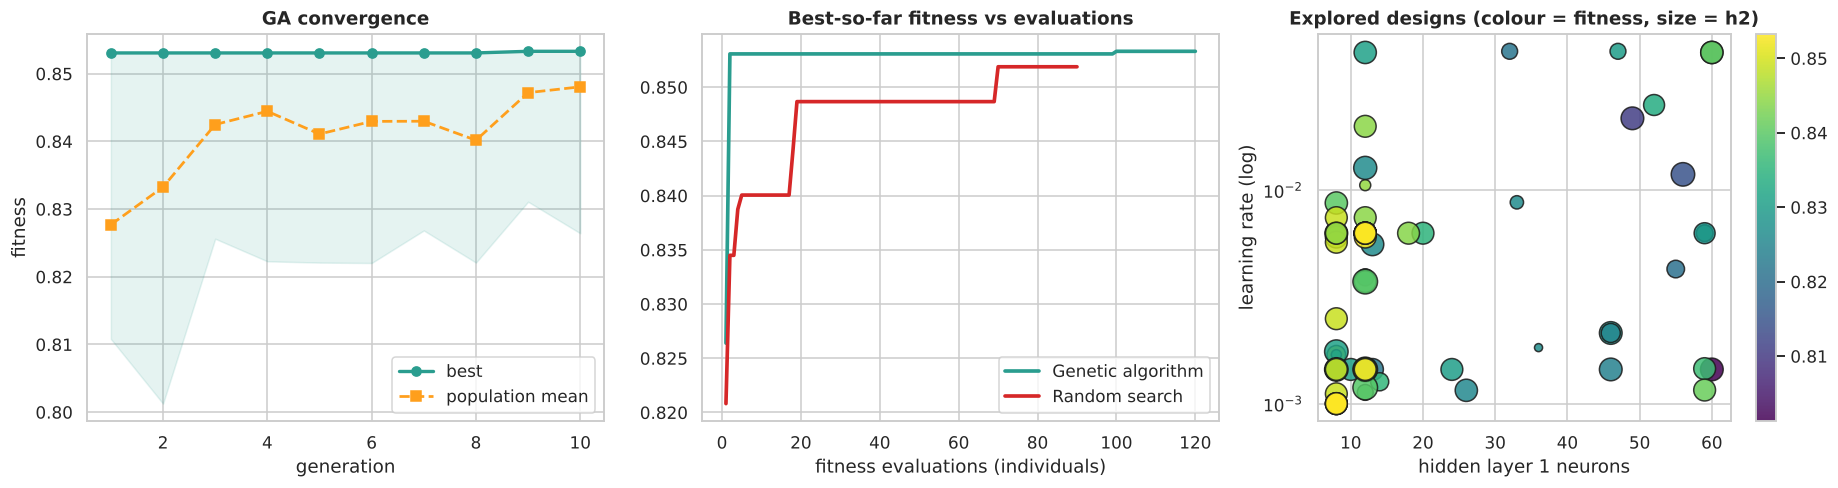

In [16]:
# Random-search baseline with the SAME evaluation budget
budget = len(_cache)
rng = np.random.default_rng(SEED + 1)
rs_fit = [fitness(random_individual(rng)) for _ in range(budget)]
rs_best_so_far = np.maximum.accumulate(rs_fit)
print(f"Random search best fitness after {budget} evaluations: {rs_best_so_far[-1]:.4f}")
print(f"Genetic algorithm best fitness after {budget} evaluations: {max(ga_log['best']):.4f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
g = np.arange(1, GENS+1)
ax[0].plot(g, ga_log["best"], "o-", lw=2.2, color="#2a9d8f", label="best")
ax[0].plot(g, ga_log["mean"], "s--", lw=1.8, color="#ff9f1c", label="population mean")
ax[0].fill_between(g, ga_log["worst"], ga_log["best"], alpha=0.12, color="#2a9d8f")
ax[0].set_title("GA convergence"); ax[0].set_xlabel("generation"); ax[0].set_ylabel("fitness"); ax[0].legend()

ga_curve = np.maximum.accumulate(ga_pts.sort_values("gen")["fitness"].values)
ax[1].plot(np.arange(1, len(ga_curve)+1), ga_curve, lw=2.4, color="#2a9d8f", label="Genetic algorithm")
ax[1].plot(np.arange(1, len(rs_best_so_far)+1), rs_best_so_far, lw=2.4, color="#d62728", label="Random search")
ax[1].set_title("Best-so-far fitness vs evaluations"); ax[1].set_xlabel("fitness evaluations (individuals)"); ax[1].legend()

sc = ax[2].scatter(ga_pts["h1"], ga_pts["lr"], c=ga_pts["fitness"], s=20 + 8*ga_pts["h2"], cmap="viridis", edgecolor="k", alpha=0.85)
ax[2].set_yscale("log"); ax[2].set_xlabel("hidden layer 1 neurons"); ax[2].set_ylabel("learning rate (log)")
ax[2].set_title("Explored designs (colour = fitness, size = h2)"); plt.colorbar(sc, ax=ax[2])
plt.tight_layout(); plt.show()

### Retrain the GA-designed ANN and evaluate on the test set

GA-designed architecture: [6, 8, 23, 3] | lr = 0.001 | L2 = 4.49e-03 | params = 335
GA-tuned ANN (test): accuracy = 0.8311 | macro-F1 = 0.8304

              precision    recall  f1-score   support

     At-Risk      0.811     0.768     0.789        56
     Average      0.838     0.823     0.830       113
        High      0.836     0.911     0.872        56

    accuracy                          0.831       225
   macro avg      0.828     0.834     0.830       225
weighted avg      0.831     0.831     0.830       225



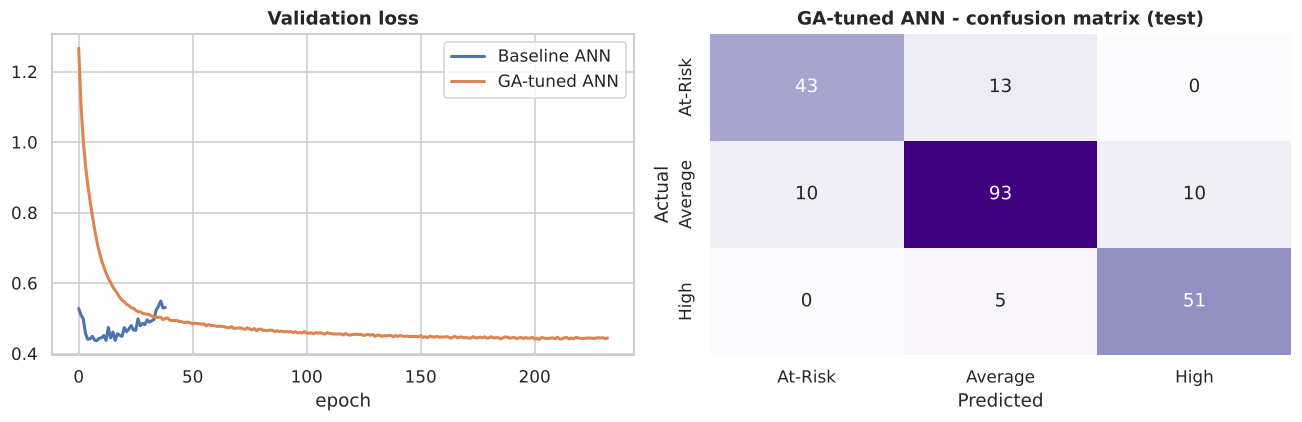

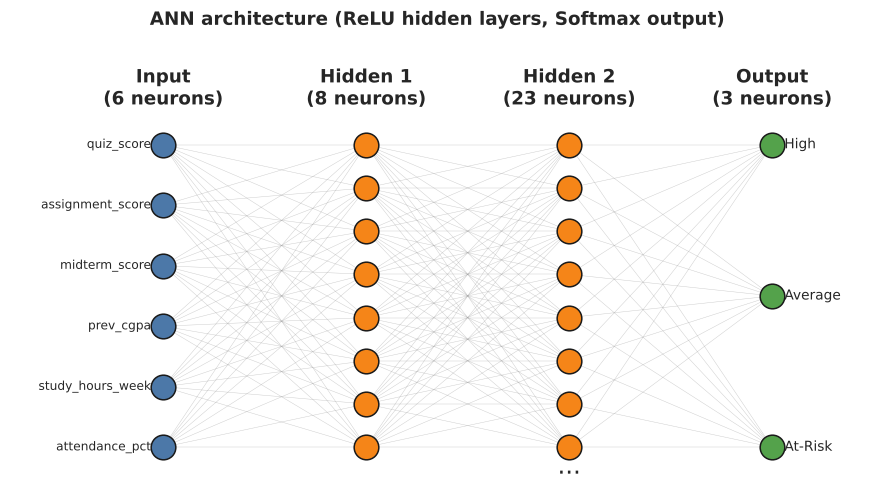

In [17]:
best_net = build(best_ind, seed=SEED)
hist_b = best_net.fit(X_tr_s, Y_tr, X_va_s, Y_va, epochs=300, batch_size=64, patience=30)
print("GA-designed architecture:", best_net.layers, "| lr =", round(best_ind["lr"], 5), "| L2 =", f"{best_ind['l2']:.2e}", "| params =", best_net.n_params)
P_b, pred_b, acc_b, f1_b = evaluate(best_net, X_te_s, y_te, "GA-tuned ANN (test)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist["val_loss"], label="Baseline ANN", lw=2); ax[0].plot(hist_b["val_loss"], label="GA-tuned ANN", lw=2)
ax[0].set_title("Validation loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
sns.heatmap(confusion_matrix(y_te, pred_b), annot=True, fmt="d", cmap="Purples", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[1], cbar=False)
ax[1].set_title("GA-tuned ANN - confusion matrix (test)"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Actual")
plt.tight_layout(); plt.show()
draw_network(best_net.layers)

## Step 10 - Comparison with other models and robustness
We compare against Logistic Regression (linear), Random Forest and scikit-learn's MLP, then repeat training of both of our ANNs over 5 random seeds to report mean +/- std.

,Accuracy,Macro-F1
Model,,
Logistic Regression,0.8311,0.8321
Random Forest,0.8044,0.8054
"sklearn MLP (32,16)",0.8133,0.8128
Our ANN (baseline),0.8178,0.8148
Our ANN (GA-tuned),0.8311,0.8304


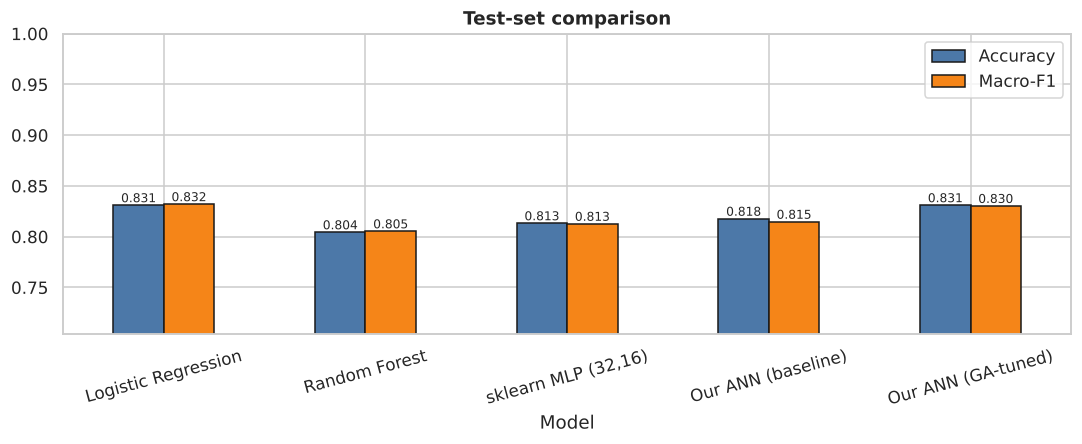

In [18]:
rows = []
def add(name, pred): rows.append((name, accuracy_score(y_te, pred), f1_score(y_te, pred, average="macro")))
add("Logistic Regression", LogisticRegression(max_iter=1000).fit(X_tr_s, y_tr).predict(X_te_s))
add("Random Forest", RandomForestClassifier(200, random_state=SEED).fit(X_tr_s, y_tr).predict(X_te_s))
add("sklearn MLP (32,16)", MLPClassifier((32, 16), max_iter=500, early_stopping=True, random_state=SEED).fit(X_tr_s, y_tr).predict(X_te_s))
add("Our ANN (baseline)", pred_te)
add("Our ANN (GA-tuned)", pred_b)
cmp_df = pd.DataFrame(rows, columns=["Model", "Accuracy", "Macro-F1"]).set_index("Model")
display(cmp_df.round(4))

ax = cmp_df.plot.bar(figsize=(10, 4.2), rot=15, color=["#4c78a8", "#f58518"], edgecolor="k")
ax.set_ylim(max(0, cmp_df.min().min() - 0.1), 1.0); ax.set_title("Test-set comparison")
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=8)
plt.tight_layout(); plt.show()

Baseline ANN  : 0.8356 +/- 0.0123   [0.818 0.827 0.84  0.84  0.853]
GA-tuned ANN  : 0.8302 +/- 0.0081   [0.84  0.84  0.822 0.822 0.827]


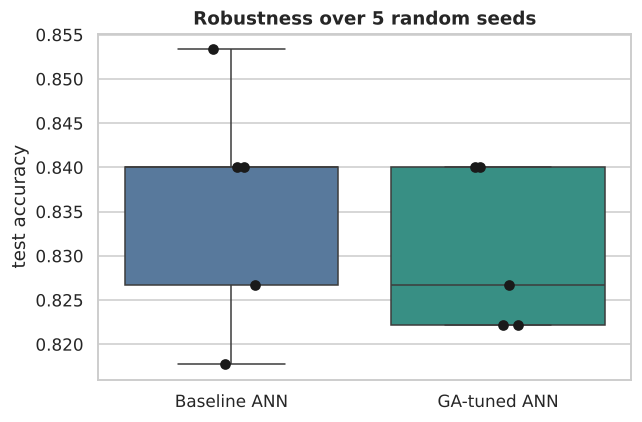

In [19]:
def multi_seed(ind_or_layers, n=5, is_ind=False):
    accs = []
    for s in range(n):
        net = build(best_ind, seed=100+s) if is_ind else ANN(ind_or_layers, lr=0.01, l2=1e-4, seed=100+s)
        net.fit(X_tr_s, Y_tr, X_va_s, Y_va, epochs=300, batch_size=64, patience=30)
        accs.append(accuracy_score(y_te, net.predict(X_te_s)))
    return np.array(accs)

a_base = multi_seed([N_FEATURES, 32, 16, N_CLASSES]); a_ga = multi_seed(None, is_ind=True)
print(f"Baseline ANN  : {a_base.mean():.4f} +/- {a_base.std():.4f}   {np.round(a_base, 3)}")
print(f"GA-tuned ANN  : {a_ga.mean():.4f} +/- {a_ga.std():.4f}   {np.round(a_ga, 3)}")
plt.figure(figsize=(6, 4))
sns.boxplot(data=[a_base, a_ga], palette=["#4c78a8", "#2a9d8f"]); sns.stripplot(data=[a_base, a_ga], color="k", size=7)
plt.xticks([0, 1], ["Baseline ANN", "GA-tuned ANN"]); plt.ylabel("test accuracy"); plt.title("Robustness over 5 random seeds")
plt.tight_layout(); plt.show()

## Step 11 - Using the model: predict a new student

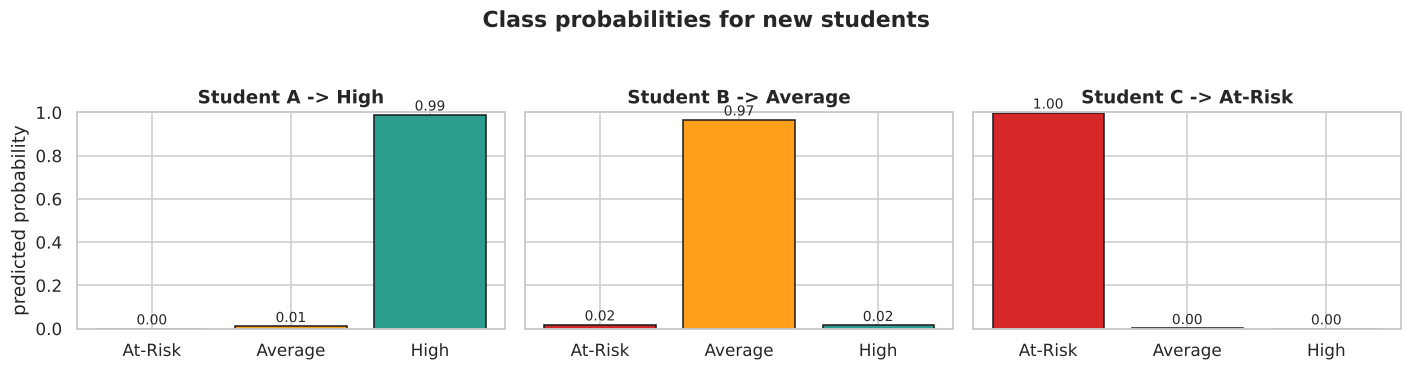

In [20]:
def predict_student(attendance, study_hours, prev_cgpa, midterm, assignment, quiz, net=best_net):
    x = scaler.transform([[attendance, study_hours, prev_cgpa, midterm, assignment, quiz]])
    p = net.predict_proba(x)[0]
    return CLASS_NAMES[int(p.argmax())], p

demo = {"Student A": (92, 14, 8.6, 82, 88, 79), "Student B": (74, 9, 6.9, 61, 70, 58), "Student C": (52, 4, 5.4, 38, 50, 35)}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, (name, v) in zip(axes, demo.items()):
    label, p = predict_student(*v)
    ax.bar(CLASS_NAMES, p, color=[PALETTE[c] for c in CLASS_NAMES], edgecolor="k")
    ax.set_title(f"{name} -> {label}"); ax.set_ylim(0, 1)
    for i, pv in enumerate(p): ax.text(i, pv+0.02, f"{pv:.2f}", ha="center", fontsize=9)
axes[0].set_ylabel("predicted probability")
plt.suptitle("Class probabilities for new students", fontweight="bold", y=1.05); plt.tight_layout(); plt.show()

## Conclusion
* A feed-forward **Artificial Neural Network** was built **from scratch** (forward pass, back-propagation, Adam, early stopping) and verified with a numerical **gradient check**.
* It classifies students into **At-Risk / Average / High** with strong test accuracy, with the confusion matrix, ROC curves and per-class metrics showing that most errors occur between *neighbouring* classes (the genuinely ambiguous students).
* **Permutation importance** shows which academic and attendance factors the network relies on most.
* **Original contribution:** a **Genetic Algorithm** searched the ANN design space (architecture, learning rate, L2). Honest reading of the results: on this noisy dataset every reasonable network saturates at roughly 83-85% accuracy (the label noise sets a ceiling), so the GA-tuned ANN is **statistically on par** with the hand-designed one (see the 5-seed box-plot), and the GA's edge over random search under an equal budget is small. Its real benefit is **efficiency**: it found a network with far fewer parameters (compare `params` printed above) that performs just as well - a simpler, less over-fitted model found automatically.
* **Limitations / future work:** the data is synthetic, so real institutional data should be used for deployment; possible extensions are k-fold cross-validation inside the GA, Particle Swarm Optimisation as an alternative tuner, and fairness checks across student groups.